# Pre-norm vs Post-norm Transformer Blocks

A transformer block has two sublayers. These are multi-head attention (MHA) and a feed-forward network (FFN). The two types of block put the LayerNorm in different places:

- **Post-norm** (the first Transformer): the norm comes after the residual add.
- **Pre-norm** (GPT-2, Llama): the norm comes before each sublayer.

This notebook shows one thing. With the same setup and no learning-rate warmup, a deep pre-norm stack trains and stays stable, more than a deep post-norm stack. We do not measure final quality. We show only that the gradients stay stable, and that the pre-norm gradient norm is lower than the post-norm gradient norm.

In [1]:
import torch
from torch import nn

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "mps"
print(device)

mps


## The blocks

Both blocks use the same two sublayers. Only the wiring around the residual add is different.

In [2]:
class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))

    def forward(self, x):
        return self.net(x)

### Post-norm

```
x = LayerNorm(x + MHA(x))
x = LayerNorm(x + FFN(x))
```

The norm is on the main path, after each residual add. The gradient goes through a LayerNorm at each layer. Each LayerNorm changes the size of the gradient with the activation statistics. In deep stacks, this can make early training not stable. You then need a careful learning-rate warmup.

In [3]:
class PostNormBlock(nn.Module):
    def __init__(self, d_model: int, nhead: int, d_ff: int):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_model, nhead, batch_first=True)
        self.ffn = FeedForward(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, attn_mask):
        attn_out, _ = self.attn(x, x, x, attn_mask=attn_mask, need_weights=False)
        x = self.norm1(x + attn_out)
        x = self.norm2(x + self.ffn(x))
        return x

### Pre-norm

```
x = x + MHA(Norm(x))
x = x + FFN(Norm(x))
```

The norm is inside the residual branch. The residual path stays clean. Thus the gradients go through it with no change in size. This is why deep pre-norm stacks train with no warmup. The block output does not go through a norm. Thus the stack needs one final LayerNorm after the last block.

In [4]:
class PreNormBlock(nn.Module):
    def __init__(self, d_model: int, nhead: int, d_ff: int):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_model, nhead, batch_first=True)
        self.ffn = FeedForward(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, attn_mask):
        h = self.norm1(x)
        attn_out, _ = self.attn(h, h, h, attn_mask=attn_mask, need_weights=False)
        x = x + attn_out
        x = x + self.ffn(self.norm2(x))
        return x

## The stack

We make a 12-layer stack of each block type. We use the same init seed, no warmup, and no clipping. Pre-norm gets the final norm. Post-norm outputs already go through norms.

In [5]:
class TransformerStack(nn.Module):
    def __init__(self, block_cls, n_layers: int, d_model: int, nhead: int, d_ff: int, vocab_size: int):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, d_model)
        self.pos = nn.Embedding(512, d_model)
        self.blocks = nn.ModuleList(block_cls(d_model, nhead, d_ff) for _ in range(n_layers))
        # Pre-norm needs a final norm. Post-norm outputs already go through norms.
        self.final_norm = nn.LayerNorm(d_model) if block_cls is PreNormBlock else nn.Identity()
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx, attn_mask):
        b, t = idx.shape
        x = self.embed(idx) + self.pos(torch.arange(t, device=idx.device))
        for block in self.blocks:
            x = block(x, attn_mask)
        return self.head(self.final_norm(x))

## The data: Tiny Shakespeare

We train a small language model on the Tiny Shakespeare text. We download the file one time. We make a character vocabulary from the text. We cut the text into fixed-length batches. The loss is next-token cross-entropy.

In [6]:
import urllib.request

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
data_path = "tiny_shakespeare.txt"
urllib.request.urlretrieve(url, data_path)

text = open(data_path).read()
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
ids = torch.tensor([stoi[c] for c in text], dtype=torch.long)
vocab_size = len(chars)
print(f"{len(text)} chars, vocab {vocab_size}")

1115394 chars, vocab 65


In [7]:
def get_batch(batch_size: int, seq_len: int):
    ix = torch.randint(len(ids) - seq_len - 1, (batch_size,))
    x = torch.stack([ids[i : i + seq_len] for i in ix])
    y = torch.stack([ids[i + 1 : i + seq_len + 1] for i in ix])
    return x.to(device), y.to(device)

## The experiment

We train each stack for the same number of steps. We use the same learning rate and no warmup. The learning rate is high, at 0.003. Deep post-norm stacks need a warmup at this learning rate. Deep pre-norm stacks do not need a warmup. At each step we record two numbers:

- the **gradient norm of the first block**. Post-norm problems show first in the early layers.
- the **training loss**. We use it to compare how stable the training is.

The proof we want:

1. All gradients stay finite in both stacks.
2. The pre-norm first-block gradient norm stays lower than the post-norm gradient norm. It has no spikes.
3. The pre-norm loss goes down with no spikes. The post-norm loss has spikes and does not go down as far.

In [8]:
d_model, nhead, d_ff, n_layers = 64, 4, 256, 12
batch_size, seq_len, n_steps, lr = 32, 64, 400, 3e-3
results = {}

for name, block_cls in [("post-norm", PostNormBlock), ("pre-norm", PreNormBlock)]:
    torch.manual_seed(42)
    model = TransformerStack(block_cls, n_layers, d_model, nhead, d_ff, vocab_size).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    grad_norms, losses = [], []
    grads_finite = True
    for step in range(n_steps):
        x, y = get_batch(batch_size, seq_len)
        opt.zero_grad()
        logits = model(x, torch.triu(torch.ones(seq_len, seq_len, dtype=torch.bool, device=device), diagonal=1))
        loss = torch.nn.functional.cross_entropy(logits.view(-1, vocab_size), y.view(-1))
        loss.backward()
        gnorm = torch.sqrt(sum((p.grad**2).sum() for p in model.blocks[0].parameters() if p.grad is not None))
        if not torch.isfinite(gnorm):
            grads_finite = False
        grad_norms.append(gnorm.item())
        losses.append(loss.item())
        opt.step()
    results[name] = {"grads": grad_norms, "loss": losses, "finite": grads_finite}
    print(f"{name:9s} | gradients finite: {grads_finite} | first loss = {losses[0]:.3f} | final loss = {losses[-1]:.3f}")

post-norm | gradients finite: True | first loss = 4.241 | final loss = 3.252
pre-norm  | gradients finite: True | first loss = 4.286 | final loss = 1.981


## Result

The plots show the first-block gradient norm (log scale) and the training loss. The numbers agree with the plots:

1. All gradients stay finite in both stacks.
2. The pre-norm first-block gradient norm stays close to 0.1 for all steps. The post-norm gradient norm spikes to 10.26, and after the spike it falls to about 1e-7. The early layers of the post-norm stack then stop learning.
3. The pre-norm loss goes down with no spikes, to 1.98. The post-norm loss has spikes, then stays near 3.3, and does not go down.

At a high learning rate with no warmup, the post-norm stack does not train in a stable way. The pre-norm stack trains in a stable way. This is the gain from the clean residual path.

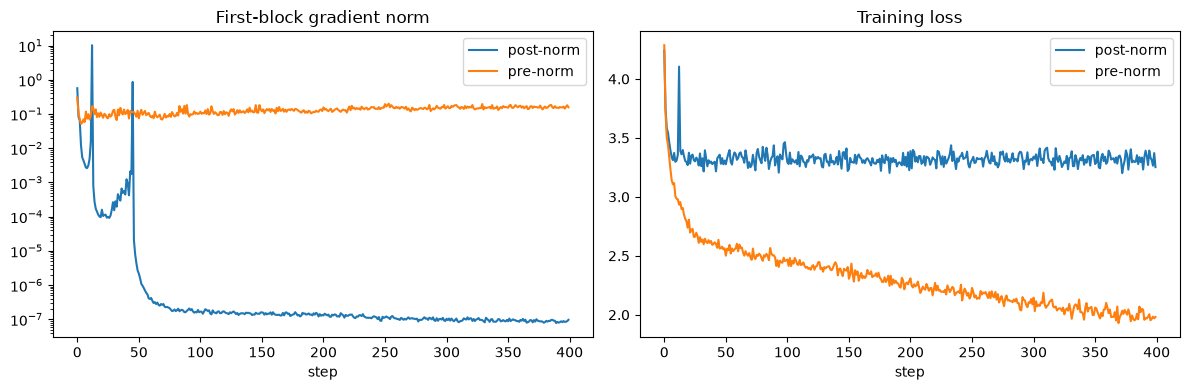

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, r in results.items():
    axes[0].plot(r["grads"], label=name)
    axes[1].plot(r["loss"], label=name)
axes[0].set_yscale("log")
axes[0].set_title("First-block gradient norm")
axes[0].set_xlabel("step")
axes[1].set_title("Training loss")
axes[1].set_xlabel("step")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()